# BEE 4750 Mini-Project 2: Dispatching New York’s Grid Under a Carbon

Price

**Names**: Kaitlyn Canivel, Claire Wang

**IDs**:

> **Due Date**
>
> Friday, 11/20/26, 9:00pm

## Overview

In 2013, New York’s grid still burned coal, ran the Indian Point nuclear
plant, and had almost no solar. In this project you will model how that
grid met demand hour by hour, find the price of electricity each hour,
and ask what impact a carbon price would have made: first by changing
which plants run, and then by changing what gets built.

### Instructions

- Students in BEE 4750 may work in groups of 2; students in BEE 5750
  work individually.
- Submit a **report of no more than 4 pages**, not counting figures,
  tables, code, and references, as a PDF to Gradescope. Answer every
  numbered question in the report and label each answer with its number
  (for example, **4.1**), then tag those pages in Gradescope.
- Put your code in an appendix or submit the notebook alongside the
  report. The report should read on its own without it.
- Parts 1–4 use linear programming, shadow prices, JuMP, and
  multi-period dispatch (October 14–28 and the October 26 lab). Part 5
  uses capacity expansion (November 2).

### Load Environment

The following code loads the environment and makes sure all needed
packages are installed. This should be at the start of most Julia
scripts.

In [2]:
import Pkg
Pkg.activate(@__DIR__)
Pkg.instantiate()

  Activating project at `~/Documents/GitHub/mp02`
┌ Warning: The project dependencies or compat requirements have changed since the manifest was last resolved.
│ It is recommended to `Pkg.resolve()` or consider `Pkg.update()` if necessary.
└ @ Pkg.API ~/.julia/juliaup/julia-1.11.5+0.aarch64.apple.darwin14/Julia-1.11.app/Contents/Resources/julia/share/julia/stdlib/v1.11/Pkg/src/API.jl:1206
   Installed DataStrings ──────── v1.1.0
   Installed libaom_jll ───────── v3.15.1+0
   Installed InlineStrings ────── v1.4.6
   Installed ColorTypes ───────── v0.12.2
   Installed HiGHS ────────────── v1.25.4
   Installed CSV ──────────────── v1.1.0
   Installed PrettyTables ─────── v3.4.8
   Installed Durations ────────── v1.2.0
   Installed StringManipulation ─ v0.5.0
   Installed JuMP ─────────────── v1.31.2
Precompiling project...
   5999.2 ms  ✓ DataStrings
   4448.5 ms  ✓ InlineStrings
   4437.6 ms  ✓ Durations
   4610.9 ms  ✓ Tables
   4614.5 ms  ✓ ColorTypes
   2898.8 ms  ✓ libaom_jll
   3996

In [3]:
using JuMP
using HiGHS
using CSV
using DataFrames
using Statistics
using Plots
using Measures

## The System

We treat New York as a single node (no transmission limits) and model
every hour of 2013.

**Demand** is NYISO’s hourly load for 2013, summed over its eleven
zones. It ranges from about 12 GW overnight to a 34 GW summer peak.

**The existing fleet** is New York’s summer 2013 generating capability,
grouped by type. Each plant type can generate up to its available
capacity in each hour. The thermal types (nuclear, coal, steam, combined
cycle, and combustion turbines) can also change their output by at most
their ramp fraction of capacity from one hour to the next. Hydro, wind,
and solar have no ramp limit.

| Type | Capacity (MW) | Variable cost (\$/MWh) | CO<sub>2</sub> (t/MWh) | Ramp (per hour) | Availability |
|:-----------|-----------:|-----------:|-----------:|-----------:|:-----------|
| Nuclear | 5,411 | 8 | 0 | 0.25 | 88% |
| Hydro | 4,276 | 0 | 0 | – | budget |
| Coal | 1,548 | 24 | 1.00 | 0.70 | 100% |
| Oil and gas steam | 9,576 | 45 | 0.58 | 0.70 | 100% |
| Combined cycle | 8,991 | 30 | 0.43 | 0.70 | 100% |
| Combustion turbine | 4,911 | 40 | 0.55 | 1 | 100% |
| Wind | 1,634 | 0 | 0 | – | profile |
| Solar | 31.5 | 0 | 0 | – | profile |

Table 1: New York’s 2013 generating fleet.

The fleet file has a ninth row, combined cycle with carbon capture, with
no capacity: New York had none in 2013. It generates nothing in Parts
1–4 and becomes an option in Part 5.

**Hydro** can be dispatched in any hour up to its capacity, but its
total generation over the year cannot exceed **24,572 GWh**, New York’s
hydro generation in 2012. Most of that capacity is the New York Power
Authority’s plants on the Niagara and St. Lawrence rivers. At Niagara, a
1950 treaty with Canada sets how much of the river’s flow must go over
the falls rather than through the turbines, which limits the water
available for power. Water used in one hour is not available in another.

**Wind and solar** follow hourly capacity-factor profiles, rescaled so
their annual averages match New York’s observed values: 23.4% for wind
and 16.5% for solar.

**Non-served energy** is allowed but penalized at \$10,000/MWh, so the
problem is always feasible. A good plan should have none.

> **Data and Simplifications**
>
> Capacities are from NYISO’s *2013 Load & Capacity Data* report (the
> “Gold Book”), Table III-3a, summer capability; wind and solar use
> nameplate capacity. Coal, combined cycle, and combustion turbine
> variable costs are roughly what these plants cost to run at 2012–13
> fuel prices, and their emissions are the values used in lecture; the
> others are course assumptions. The wind capacity factor is from the
> Gold Book’s 2012 energy for wind plants in service all year, and the
> solar capacity factor is the Long Island Solar Farm’s in NYISO’s 2024
> Gold Book. The ramp fractions are hourly limits: coal’s and combined
> cycle’s are the rates of the large units in the RTS-GMLC test system
> (about 4 MW per minute on a 350 MW unit), steam is assumed to match
> coal, combustion turbines can reach full output within an hour, and
> nuclear’s is a course assumption.
>
> The model leaves out imports (New York imported roughly 15% of its
> electricity), pumped storage (1,407 MW), about 400 MW of small biomass
> and waste plants, and transmission limits between zones.

For comparison, in 2012 New York generated 139,137 GWh in-state: 29.4%
nuclear, 17.7% hydro, 2.2% wind, and 48.1% fossil, of which coal was
3.1%.

The data, ready to use:

In [4]:
# Statewide hourly demand: the sum of NYISO's eleven load zones [MW]
load_data = DataFrame(CSV.File("data/2013_hourly_load_NY.csv"))
zones = ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K"]
demand = zeros(nrow(load_data))
for zone in zones
    demand .+= load_data[:, zone]
end

# Hourly wind and solar capacity factors, rescaled to New York's annual averages
profiles = DataFrame(CSV.File("data/wind_solar_capacity_factors.csv"))
wind_cf = profiles.Wind .* (0.234 / mean(profiles.Wind))
solar_cf = profiles.Solar .* (0.165 / mean(profiles.Solar))

# The existing fleet, as in the table above. Wind and solar availability come
# from the hourly profiles, not the Availability column. RampFraction is missing
# for hydro, wind and solar, which have no ramp limit. The last row, combined
# cycle with carbon capture, has no capacity until Part 5.
fleet = DataFrame(CSV.File("data/nyca_2013_fleet.csv"))

hydro_budget = 24_572_000   # annual hydro energy [MWh]
nse_cost = 10_000           # penalty on non-served energy [$/MWh]

10000

## Problems (Total: 100 Points)

### Part 1: Formulate the Dispatch Problem (15 points)

#### Problem 1.1 (15 points)

Formulate a linear program that decides how much each plant type
generates in every hour of 2013 to meet demand at the lowest total
variable cost. Define your decision variables (with units), objective,
and constraints: meeting demand each hour, each plant’s hourly
availability, ramping limits for the thermal types, and the hydro energy
budget. Explain each constraint in a sentence.

In [5]:
n_plants = nrow(fleet) - 1
tot_hours = 24*365

# availability data including solar and wind capacity factors
availability = ones(n_plants, tot_hours)
availability[1, :] .= fleet[1, :Availability]
availability[7, :] = wind_cf
availability[8, :] = solar_cf

# clean up ramp fraction to be usable
ramp_fraction = ones(n_plants)
ramp_fraction = coalesce.(fleet[:,:RampFraction],1)

# set up optimization model
dispatch = Model(HiGHS.Optimizer)
@variable(dispatch, y[g in 1:n_plants, t in 1:tot_hours] >= 0)
#@objective(dispatch, Min, sum(fleet[g, :VarCost] * y[g,t] for g in 1:n_plants, t in 1:tot_hours) + nse_cost*sum(sum(y[g,t] for g in 1:n_plants) - demand[t] for t in 1:tot_hours))
@objective(dispatch, Min, sum(sum((fleet[g, :VarCost] * y[g,t]) for g in 1:n_plants) + nse_cost*(sum(y[g,t] for g in 1:n_plants) - demand[t]) for t in 1:tot_hours))
@constraint(dispatch, demand_constaint[t in 1:tot_hours], sum(y[:,t]) >= demand[t])                                               # demand constraint
@constraint(dispatch, capacity[g in 1:n_plants, t in 1:tot_hours], y[g,t] <= fleet[g, :Capacity] * availability[g,t])             # capacity constraint
@constraint(dispatch, ramp_up[g in 1:n_plants, t in 1:(tot_hours-1)], y[g,t+1] - y[g,t] <= ramp_fraction[g] * fleet[g,:Capacity]) # ramping constraint
@constraint(dispatch, ramp_down[g in 1:n_plants, t in 1:(tot_hours-1)], y[g,t] - y[g,t+1] <= ramp_fraction[g] * fleet[g,:Capacity]) # ramping constraint
@constraint(dispatch, hydro_constraint, sum(y[2,t] for t in 1:tot_hours) <= hydro_budget)

set_silent(dispatch)

### Part 2: Dispatching New York in 2013 (20 points)

#### Problem 2.1 (10 points)

Solve your model in JuMP with no carbon tax. Report the total variable
cost, annual CO<sub>2</sub> emissions, each plant type’s share of
generation, and any non-served energy. Compare your generation shares
with New York’s actual 2012 shares above, and give two reasons for the
largest differences.

In [6]:
optimize!(dispatch)
termination_status(dispatch)

OPTIMAL::TerminationStatusCode = 1

In [7]:
@show objective_value(dispatch);
total_cost = objective_value(dispatch)
generation_matrix = value.(y)

# each plant type's share of generation
total_generation_per_plant = vec(sum(generation_matrix,dims=2)) ./ 1000 # in GWh
total_annual_generation = sum(generation_matrix) / 1000 # in GWh
gen_share_per_plant = (total_generation_per_plant ./ total_annual_generation) .* 100

# non-served energy calculations
total_hourly_generation = vec(sum(generation_matrix, dims=1))
not_served = demand .- total_hourly_generation
total_annual_not_served = sum(not_served)

# annual CO2 emissions
co2_emissions = sum(total_generation_per_plant .* fleet[1:8,:Emissions]) * 1000 # convert back to MWh

# display values
println("Total annual generation: $total_annual_generation GWh")
println("Total CO2 emissions: $co2_emissions tons")
println("Generation share per plant tye: $gen_share_per_plant %")
println("Non-served energy: $total_annual_not_served MWh")

objective_value(dispatch) = 3.148113067074813e9
Total annual generation: 163513.88924999995 GWh
Total CO2 emissions: 4.900927684433876e7 tons
Generation share per plant tye: [25.509953308139377, 15.0274696007208, 8.293167058895582, 0.7735933463552325, 44.54218566833163, 3.7773739634477366, 2.0484122635472106, 0.027844790561117386] %
Non-served energy: 5.4569682106375694e-12 MWh


#### Problem 2.2 (10 points)

Plot hourly generation by plant type, stacked, for one week in July.
Explain how the model uses hydro, given its annual budget.

In [8]:
using Pkg
Pkg.add(["Colors", "ColorSchemes"])

    Updating registry at `~/.julia/registries/General.toml`
   Resolving package versions...
  No Changes to `~/Documents/GitHub/mp02/Project.toml`
  No Changes to `~/Documents/GitHub/mp02/Manifest.toml`


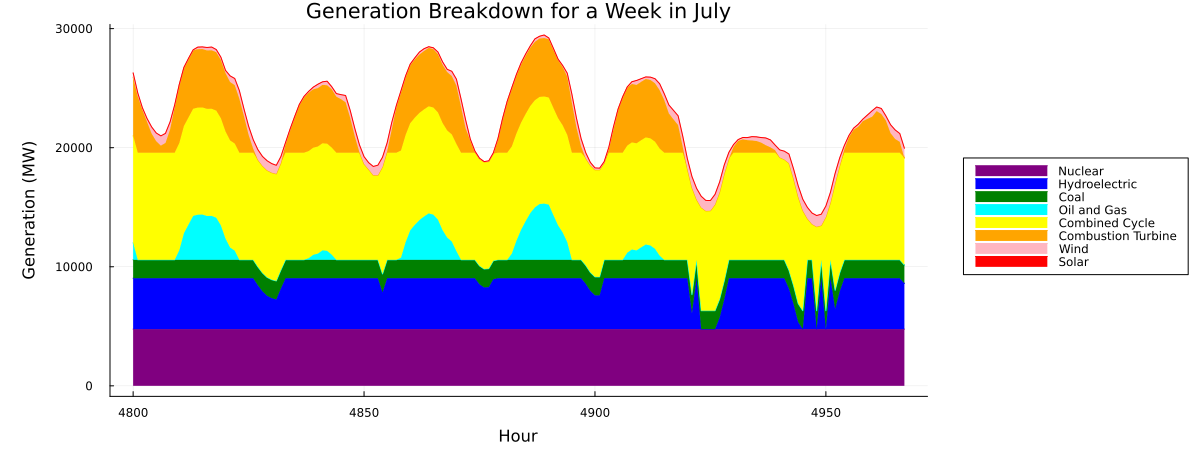

In [9]:
weekly_hours = vec([24*200, 24*207])

resources = ["Nuclear", "Hydroelectric", "Coal", "Oil and Gas", "Combined Cycle", "Combustion Turbine", "Wind", "Solar"]
resource_colors = [:purple, :blue, :green, :cyan, :yellow, :orange, :lightpink, :red]

by_resource = zeros(weekly_hours[2] - weekly_hours[1], length(resources))

for t in weekly_hours[1]:(weekly_hours[2]-1)
    for g in 1:n_plants
        by_resource[t-(weekly_hours[1]-1),g] = generation_matrix[g,t]
    end
end

areaplot(range(weekly_hours[1], weekly_hours[2]-1), by_resource, color=permutedims(resource_colors),
    xlabel="Hour", ylabel="Generation (MW)", legend=:outerright, label=permutedims(resources),
    size=(1200,460), left_margin=10mm, bottom_margin=8mm, title="Generation Breakdown for a Week in July", yformatter=:plain)

In [10]:
display(by_resource)

168×8 Matrix{Float64}:
 4761.68  4276.0   1548.0  1433.56   8991.0  4911.0    358.556   -0.0
 4761.68  4276.0   1548.0     0.0    8991.0  4742.48   276.143   -0.0
 4761.68  4276.0   1548.0     0.0    8991.0  3627.88   151.437   -0.0
 4761.68  4276.0   1548.0     0.0    8991.0  2613.36   267.155   -0.0
 4761.68  4276.0   1548.0     0.0    8991.0  1619.35   547.468   -0.0
 4761.68  4276.0   1548.0     0.0    8991.0   967.813  686.107   -0.0
 4761.68  4276.0   1548.0     0.0    8991.0   598.105  815.615   -0.0
 4761.68  4276.0   1548.0     0.0    8991.0   822.419  801.901   -0.0
 4761.68  4276.0   1548.0     0.0    8991.0  1960.41   620.281    6.83203
 4761.68  4276.0   1548.0     0.0    8991.0  3879.74   124.716   10.4631
 4761.68  4276.0   1548.0   809.702  8991.0  4911.0     14.7157  12.6027
 4761.68  4276.0   1548.0  2240.26   8991.0  4911.0      6.3815  13.0781
 4761.68  4276.0   1548.0  2969.08   8991.0  4911.0     39.9358  12.0026
    ⋮                                           ⋮  

### Part 3: The Value of Water (10 points)

#### Problem 3.1 (10 points)

Report the shadow price of the hydro budget and interpret it. Suppose
enough extra water could be diverted through the Niagara turbines to
generate one more MWh over the year: what would that MWh be worth, and
why that value? Be careful with the sign.

In [11]:
fix_discrete_variables(dispatch)
optimize!(dispatch)
termination_status(dispatch)

OPTIMAL::TerminationStatusCode = 1

In [12]:
display(shadow_price.(hydro_constraint))

-30.0

### Part 4: A Carbon Tax (25 points)

#### Problem 4.1 (15 points)

Add a carbon tax of $\tau$ dollars per tonne of CO<sub>2</sub> to your
model, and show how it enters your objective. Solve the dispatch problem
with taxes of \$0, \$20, \$40, \$60, and \$100 per tonne, and report
annual emissions and each fossil plant type’s share of generation at
each tax in a table. Between which taxes do emissions drop, and which
plant type moves ahead of coal in each? Why does coal keep running after
it falls behind combined cycle plants?

In [ ]:
taxes = [0, 20, 40, 60, 100]                 # carbon tax [$/tonne CO2]
tax_emissions = zeros(length(taxes))         # annual emissions [million tonnes]
tax_shares = zeros(length(taxes), n_plants)  # share of generation [%]

for (i, tax) in enumerate(taxes)
    # set up optimization model with the carbon tax added to each plant's cost
    dispatch = Model(HiGHS.Optimizer)
    @variable(dispatch, y[g in 1:n_plants, t in 1:tot_hours] >= 0)
    @variable(dispatch, non_served[t in 1:tot_hours] >= 0)
    @objective(dispatch, Min, sum((fleet[g, :VarCost] + tax * fleet[g, :Emissions]) * y[g,t] for g in 1:n_plants, t in 1:tot_hours) + nse_cost*sum(non_served))
    @constraint(dispatch, demand_constraint[t in 1:tot_hours], sum(y[g,t] for g in 1:n_plants) + non_served[t] >= demand[t])           # demand constraint
    @constraint(dispatch, capacity[g in 1:n_plants, t in 1:tot_hours], y[g,t] <= fleet[g, :Capacity] * availability[g,t])               # capacity constraint
    @constraint(dispatch, ramp_up[g in 1:n_plants, t in 1:(tot_hours-1)], y[g,t+1] - y[g,t] <= ramp_fraction[g] * fleet[g,:Capacity])   # ramping constraint
    @constraint(dispatch, ramp_down[g in 1:n_plants, t in 1:(tot_hours-1)], y[g,t] - y[g,t+1] <= ramp_fraction[g] * fleet[g,:Capacity]) # ramping constraint
    @constraint(dispatch, hydro_constraint, sum(y[hydro,t] for t in 1:tot_hours) <= hydro_budget)                                       # hydro energy budget
    set_silent(dispatch)
    optimize!(dispatch)

    generation_matrix = value.(y)
    total_generation_per_plant = vec(sum(generation_matrix, dims=2))   # in MWh
    tax_shares[i, :] = (total_generation_per_plant ./ sum(generation_matrix)) .* 100
    tax_emissions[i] = sum(total_generation_per_plant .* fleet[1:n_plants, :Emissions]) / 1e6
end

tax_table = DataFrame(
    Tax = taxes,
    Emissions_Mt = tax_emissions,
    Coal_pct = tax_shares[:, coal],
    Oil_Gas_pct = tax_shares[:, oil_gas],
    Combined_Cycle_pct = tax_shares[:, combined_cycle],
    Combustion_Turbine_pct = tax_shares[:, combustion_turbine],
)
display(tax_table)

# effective merit-order cost at each tax [$/MWh]: variable cost plus tax times emissions rate
for tax in taxes
    effective_cost = [fleet[g, :VarCost] + tax * fleet[g, :Emissions] for g in (coal, oil_gas, combined_cycle, combustion_turbine)]
    println("Tax $tax, effective cost [coal, oil and gas, combined cycle, combustion turbine]: $(round.(effective_cost, digits=2))")
end

# tax at which a cleaner, more expensive plant type overtakes a dirtier, cheaper one
cc_passes_coal = (fleet[combined_cycle, :VarCost] - fleet[coal, :VarCost]) / (fleet[coal, :Emissions] - fleet[combined_cycle, :Emissions])
cc_passes_oil_gas = (fleet[combined_cycle, :VarCost] - fleet[oil_gas, :VarCost]) / (fleet[oil_gas, :Emissions] - fleet[combined_cycle, :Emissions])
ct_passes_coal = (fleet[combustion_turbine, :VarCost] - fleet[coal, :VarCost]) / (fleet[coal, :Emissions] - fleet[combustion_turbine, :Emissions])
println("Combined cycle passes coal at a tax of $cc_passes_coal")
println("Combined cycle passes oil and gas at a tax of $cc_passes_oil_gas")
println("Combustion turbine passes coal at a tax of $ct_passes_coal")


Row,Tax,Emissions_Mt,Coal_pct,Oil_Gas_pct,Combined_Cycle_pct,Combustion_Turbine_pct
,Int64,Float64,Float64,Float64,Float64,Float64
1,0,49.0093,8.29317,0.773593,44.5422,3.77737
2,20,46.0791,5.14928,0.773593,47.6861,3.77737
3,40,42.7199,0.584066,0.773593,47.6861,8.34258
4,60,42.322,0.00500891,1.34718,47.6861,8.34805
5,100,42.322,0.00500891,1.34718,47.6861,8.34805


Tax 0, effective cost [coal, oil and gas, combined cycle, combustion turbine]: [24.0, 45.0, 30.0, 40.0]
Tax 20, effective cost [coal, oil and gas, combined cycle, combustion turbine]: [44.0, 56.6, 38.6, 51.0]
Tax 40, effective cost [coal, oil and gas, combined cycle, combustion turbine]: [64.0, 68.2, 47.2, 62.0]
Tax 60, effective cost [coal, oil and gas, combined cycle, combustion turbine]: [84.0, 79.8, 55.8, 73.0]
Tax 100, effective cost [coal, oil and gas, combined cycle, combustion turbine]: [124.0, 103.0, 73.0, 95.0]
Combined cycle passes coal at a tax of 10.526315789473683
Combined cycle passes oil and gas at a tax of -100.00000000000003
Combustion turbine passes coal at a tax of 35.55555555555556


#### Problem 4.2 (10 points)

Is there any tax that brings emissions below 40 million tonnes per year
by changing only which existing plants run? Identify the lowest
emissions redispatch can reach, and explain what sets that floor.

In [19]:
dispatch = Model(HiGHS.Optimizer)
@variable(dispatch, y[g in 1:n_plants, t in 1:tot_hours] >= 0)
@variable(dispatch, non_served[t in 1:tot_hours] >= 0)
@expression(dispatch, emissions, sum(fleet[g, :Emissions] * y[g,t] for g in 1:n_plants, t in 1:tot_hours))
@constraint(dispatch, demand_constraint[t in 1:tot_hours], sum(y[g,t] for g in 1:n_plants) + non_served[t] >= demand[t])           # demand constraint
@constraint(dispatch, capacity[g in 1:n_plants, t in 1:tot_hours], y[g,t] <= fleet[g, :Capacity] * availability[g,t])               # capacity constraint
@constraint(dispatch, ramp_up[g in 1:n_plants, t in 1:(tot_hours-1)], y[g,t+1] - y[g,t] <= ramp_fraction[g] * fleet[g,:Capacity])   # ramping constraint
@constraint(dispatch, ramp_down[g in 1:n_plants, t in 1:(tot_hours-1)], y[g,t] - y[g,t+1] <= ramp_fraction[g] * fleet[g,:Capacity]) # ramping constraint
@constraint(dispatch, hydro_constraint, sum(y[hydro,t] for t in 1:tot_hours) <= hydro_budget)                                       # hydro energy budget
set_silent(dispatch)

# lowest possible emissions: minimize emissions, with a large penalty so that no energy goes unserved
@objective(dispatch, Min, emissions + 1e6*sum(non_served))
optimize!(dispatch)

min_emissions = value(emissions) / 1e6
println("Lowest emissions from redispatch: $min_emissions million tonnes")
println("Non-served energy: $(sum(value.(non_served))) MWh")
println("Below 40 million tonnes? $(min_emissions < 40)")

# generation share at the floor, to see what sets it
generation_matrix = value.(y)
total_generation_per_plant = vec(sum(generation_matrix, dims=2))
gen_share_per_plant = (total_generation_per_plant ./ sum(generation_matrix)) .* 100
println("Generation share per plant type at the floor: $(round.(gen_share_per_plant, digits=2)) %")

# very high taxes: emissions should level off at the floor
for tax in [200, 1000, 5000]
    @objective(dispatch, Min, sum((fleet[g, :VarCost] + tax * fleet[g, :Emissions]) * y[g,t] for g in 1:n_plants, t in 1:tot_hours) + nse_cost*sum(non_served))
    optimize!(dispatch)
    println("Tax $tax: emissions $(round(value(emissions) / 1e6, digits=3)) million tonnes, non-served energy $(round(sum(value.(non_served)), digits=1)) MWh")
end

Lowest emissions from redispatch: 42.32199968337961 million tonnes
Non-served energy: 0.0 MWh
Below 40 million tonnes? false
Generation share per plant type at the floor: [25.51, 15.03, 0.01, 1.35, 47.69, 8.35, 2.05, 0.03] %
Tax 200: emissions 42.322 million tonnes, non-served energy 0.0 MWh
Tax 1000: emissions 42.322 million tonnes, non-served energy 0.0 MWh
Tax 5000: emissions 42.322 million tonnes, non-served energy 0.0 MWh


### Part 5: Building New Capacity (30 points)

The state can now build six kinds of new capacity: combined cycle,
combustion turbines, wind, solar, hydro, and combined cycle with carbon
capture. New capacity behaves like the existing plants of the same type:
the same variable cost, emissions, and availability, and for the gas
plants the same ramp fraction. Two of the six need more detail:

- **Hydro.** The only sites are existing dams that have no turbines, so
  at most 295 MW can be built. We assume each MW of new hydro generates,
  on average, as much as each MW of existing hydro: each new MW raises
  the annual hydro generating capacity by 24,572,000 MWh ÷ 4,276 MW ≈
  5,746 MWh.
- **Combined cycle with carbon capture.** This is the fleet file’s last
  row. It captures 90% of its CO<sub>2</sub>, so it emits 0.05 t/MWh. It
  costs \$39/MWh to run, more than a combined cycle plant, because it
  burns more gas and pays to move and store the CO<sub>2</sub> it
  captures.

Annualized costs of new capacity are in `data/new_capacity_costs.csv`
(in \$ per MW of capacity per year): `Cost2013` is from 2013 cost
estimates and `CostToday` from 2025 ones.

In [20]:
new_costs = DataFrame(CSV.File("data/new_capacity_costs.csv"))
hydro_build_limit = 295   # most new hydro that can be built [MW]

295

> **New Capacity: Data and Cautions**
>
> The annualized costs are capital costs from the U.S. Energy
> Information Administration’s 2013 and 2025 reports on new generating
> plants, spread over 30 years at 7%, plus fixed operating costs. The
> 295 MW of hydro is Oak Ridge National Laboratory’s 2012 estimate of
> the capacity that New York’s dams without turbines could support.
> Capture’s variable cost of \$39/MWh includes about \$4.50/MWh to move
> and store the 0.45 t of CO<sub>2</sub> it captures from each MWh, at
> \$10 per tonne.
>
> Keep two things in mind when you interpret your results. First, the
> 2013 cost of capture is an estimate for a kind of plant that had not
> been built at commercial scale. Second, the two reports describe
> different hydro plants, 500 MW in 2013 and 100 MW in 2025, so part of
> the increase in hydro’s cost between them comes from comparing a
> larger plant with a smaller one, not from a change in what the same
> plant costs.

#### Problem 5.1 (8 points)

Extend your model to include build decisions, using 2013 costs. Explain
what changes in the objective and the constraints. With no emissions
policy, what does the model build, and why? Compare the cost of a MWh
from new wind with the cost of the fuel it would replace.

In [21]:
# row numbers in the fleet file
hydro = 2
coal = 3
oil_gas = 4
combined_cycle = 5
combustion_turbine = 6
wind = 7
solar = 8
ccs = 9

# the six kinds of new capacity, as fleet rows. CHECK: this order must match the
# row order of new_capacity_costs.csv (run show(new_costs) to confirm)
new_types = [combined_cycle, combustion_turbine, wind, solar, hydro, ccs]
new_names = ["Combined Cycle", "Combustion Turbine", "Wind", "Solar", "Hydro", "Combined Cycle + Capture"]
n_new = length(new_types)
n_types = nrow(fleet)                        # existing plant types plus carbon capture
k_wind = findfirst(==(wind), new_types)
k_hydro = findfirst(==(hydro), new_types)
hydro_mwh_per_mw = hydro_budget / 4_276      # annual energy from each new MW of hydro [MWh/MW]

# availability of each kind of new capacity (same as the existing plants of that type)
new_availability = zeros(n_new, tot_hours)
for k in 1:n_new
    if new_types[k] <= n_plants
        new_availability[k, :] = availability[new_types[k], :]
    else
        new_availability[k, :] .= fleet[new_types[k], :Availability]
    end
end


# Capacity expansion model.
#   cost_column: :Cost2013 or :CostToday
#   emissions_cap: annual CO2 cap [tonnes] (Inf means no cap)
#   carbon_tax: tax on CO2 [$/tonne]
function solve_expansion(cost_column; emissions_cap=Inf, carbon_tax=0)
    expansion = Model(HiGHS.Optimizer)
    @variable(expansion, y[g in 1:n_plants, t in 1:tot_hours] >= 0)          # existing plants' generation [MW]
    @variable(expansion, build[k in 1:n_new] >= 0)                           # new capacity built [MW]
    @variable(expansion, y_new[k in 1:n_new, t in 1:tot_hours] >= 0)         # new plants' generation [MW]
    @variable(expansion, non_served[t in 1:tot_hours] >= 0)                  # non-served energy [MWh]
    @expression(expansion, emissions,
        sum(fleet[g, :Emissions] * y[g,t] for g in 1:n_plants, t in 1:tot_hours) +
        sum(fleet[new_types[k], :Emissions] * y_new[k,t] for k in 1:n_new, t in 1:tot_hours))

    @objective(expansion, Min,
        sum(fleet[g, :VarCost] * y[g,t] for g in 1:n_plants, t in 1:tot_hours) +
        sum(fleet[new_types[k], :VarCost] * y_new[k,t] for k in 1:n_new, t in 1:tot_hours) +
        carbon_tax * emissions +
        sum(new_costs[k, cost_column] * build[k] for k in 1:n_new) +
        nse_cost*sum(non_served))

    @constraint(expansion, demand_constraint[t in 1:tot_hours], sum(y[g,t] for g in 1:n_plants) + sum(y_new[k,t] for k in 1:n_new) + non_served[t] >= demand[t])  # demand constraint
    @constraint(expansion, capacity[g in 1:n_plants, t in 1:tot_hours], y[g,t] <= fleet[g, :Capacity] * availability[g,t])                                       # capacity constraint
    @constraint(expansion, new_capacity[k in 1:n_new, t in 1:tot_hours], y_new[k,t] <= build[k] * new_availability[k,t])                                         # capacity constraint for new plants
    @constraint(expansion, ramp_up[g in 1:n_plants, t in 1:(tot_hours-1)], y[g,t+1] - y[g,t] <= ramp_fraction[g] * fleet[g,:Capacity])                           # ramping constraint
    @constraint(expansion, ramp_down[g in 1:n_plants, t in 1:(tot_hours-1)], y[g,t] - y[g,t+1] <= ramp_fraction[g] * fleet[g,:Capacity])                         # ramping constraint
    @constraint(expansion, new_ramp_up[k in 1:n_new, t in 1:(tot_hours-1)], y_new[k,t+1] - y_new[k,t] <= ramp_fraction[new_types[k]] * build[k])                 # ramping constraint for new plants
    @constraint(expansion, new_ramp_down[k in 1:n_new, t in 1:(tot_hours-1)], y_new[k,t] - y_new[k,t+1] <= ramp_fraction[new_types[k]] * build[k])               # ramping constraint for new plants
    @constraint(expansion, hydro_build_constraint, build[k_hydro] <= hydro_build_limit)                                                                          # limit on new hydro sites
    @constraint(expansion, hydro_constraint, sum(y[hydro,t] for t in 1:tot_hours) + sum(y_new[k_hydro,t] for t in 1:tot_hours) <= hydro_budget + hydro_mwh_per_mw * build[k_hydro])  # hydro energy budget
    if isfinite(emissions_cap)
        @constraint(expansion, emissions_constraint, emissions <= emissions_cap)                                                                                 # emissions cap
    end

    set_silent(expansion)
    optimize!(expansion)
    return expansion
end


# each plant type's share of generation [%], existing and new plants combined (length n_types)
function generation_share(model)
    generation_by_type = zeros(n_types)
    generation_by_type[1:n_plants] = vec(sum(value.(model[:y]), dims=2))
    generation_new = value.(model[:y_new])
    for k in 1:n_new
        generation_by_type[new_types[k]] += sum(generation_new[k, :])
    end
    return (generation_by_type ./ sum(generation_by_type)) .* 100
end


expansion = solve_expansion(:Cost2013)

display(DataFrame(Type = new_names, Built_MW = round.(value.(expansion[:build]), digits=1)))
println("Total cost: $(objective_value(expansion))")
println("Annual CO2 emissions: $(value(expansion[:emissions]) / 1e6) million tonnes")
println("Generation share per plant type: $(round.(generation_share(expansion), digits=2)) %")

# cost of a MWh from new wind compared with the cost of the fuel it would replace [$/MWh]
wind_cost_per_mwh = new_costs[k_wind, :Cost2013] / sum(wind_cf)
println("New wind, annualized cost per MWh: $wind_cost_per_mwh")
println("Variable cost [coal, oil and gas, combined cycle, combustion turbine]: $([fleet[g, :VarCost] for g in (coal, oil_gas, combined_cycle, combustion_turbine)])")


Row,Type,Built_MW
,String,Float64
1,Combined Cycle,0.0
2,Combustion Turbine,0.0
3,Wind,0.0
4,Solar,0.0
5,Hydro,0.0
6,Combined Cycle + Capture,0.0


Total cost: 3.148113067405985e9
Annual CO2 emissions: 49.00927684434034 million tonnes
Generation share per plant type: [25.51, 15.03, 8.29, 0.77, 44.54, 3.78, 2.05, 0.03, 0.0] %
New wind, annualized cost per MWh: 106.29512547320766
Variable cost [coal, oil and gas, combined cycle, combustion turbine]: [24, 45, 30, 40]


#### Problem 5.2 (10 points)

Cap annual emissions at 40 million tonnes, still with 2013 costs. What
does the model build, what does the system cost, and what is the shadow
price of the cap? Explain what the new plants replace.

In [22]:
emissions_cap = 40e6                                       # annual emissions cap [tonnes]

expansion_no_cap = expansion                               # uncapped solution from 5.1, for comparison
expansion = solve_expansion(:Cost2013, emissions_cap=emissions_cap)

display(DataFrame(Type = new_names, Built_MW = round.(value.(expansion[:build]), digits=1)))
println("Total cost: $(objective_value(expansion))")
println("Annual CO2 emissions: $(value(expansion[:emissions]) / 1e6) million tonnes")
println("Shadow price of the cap: $(-shadow_price(expansion[:emissions_constraint])) \$/tonne")   # sign flipped: minimization, <= constraint

# what the new plants replace: compare generation shares with and without the cap
share_no_cap = generation_share(expansion_no_cap)
share_cap = generation_share(expansion)
plant_names = ["Nuclear", "Hydro", "Coal", "Oil and Gas", "Combined Cycle", "Combustion Turbine", "Wind", "Solar", "Combined Cycle + Capture"]
display(DataFrame(Type = plant_names, No_Cap_pct = round.(share_no_cap, digits=2), Cap_pct = round.(share_cap, digits=2), Change_pp = round.(share_cap .- share_no_cap, digits=2)))


Row,Type,Built_MW
,String,Float64
1,Combined Cycle,369.3
2,Combustion Turbine,0.0
3,Wind,0.0
4,Solar,0.0
5,Hydro,295.0
6,Combined Cycle + Capture,240.8


Total cost: 3.373768995694325e9
Annual CO2 emissions: 39.999999999996945 million tonnes
Shadow price of the cap: 57.79590242731121 $/tonne


Row,Type,No_Cap_pct,Cap_pct,Change_pp
,String,Float64,Float64,Float64
1,Nuclear,25.51,25.51,0.0
2,Hydro,15.03,16.06,1.04
3,Coal,8.29,0.0,-8.29
4,Oil and Gas,0.77,0.98,0.2
5,Combined Cycle,44.54,49.28,4.74
6,Combustion Turbine,3.78,4.8,1.02
7,Wind,2.05,2.05,0.0
8,Solar,0.03,0.03,0.0
9,Combined Cycle + Capture,0.0,1.29,1.29


#### Problem 5.3 (12 points)

Repeat 5.2’s capped problem with today’s costs. What gets built now, and
what is the shadow price of the same cap? Then remove the cap and
instead impose a carbon tax equal to that shadow price. Compare the two
solutions, and explain the result using what you know about shadow
prices. What does the change from 5.2 tell you about the role of a
carbon price when technology costs fall?

> **Working With JuMP Output**
>
> `value.(x)` returns a JuMP container; use `value.(x).data` or index it
> with `value(x[g, t])` to get plain numbers for plotting. End cells
> that build large sets of variables or constraints with a semicolon to
> suppress long printed output. For a constraint `c`, `shadow_price(c)`
> reports how the objective changes as the constraint is relaxed; check
> its sign against your intuition. `fleet.RampFraction` is `missing` for
> the types with no ramp limit; test for that with `ismissing`.

In [23]:

emissions_cap = 40e6                                       # annual emissions cap [tonnes]

# capped problem with today's costs
expansion_cap = solve_expansion(:CostToday, emissions_cap=emissions_cap)
cap_price = -shadow_price(expansion_cap[:emissions_constraint])   # [$/tonne], sign flipped: minimization, <= constraint

display(DataFrame(Type = new_names, Built_MW = round.(value.(expansion_cap[:build]), digits=1)))
println("Total cost with the cap: $(objective_value(expansion_cap))")
println("Shadow price of the cap: $cap_price \$/tonne")

# remove the cap and impose a carbon tax equal to the shadow price
expansion_tax = solve_expansion(:CostToday, carbon_tax=cap_price)
tax_emissions = value(expansion_tax[:emissions])
tax_revenue = cap_price * tax_emissions

display(DataFrame(Type = new_names, Built_MW = round.(value.(expansion_tax[:build]), digits=1)))
println("Annual CO2 emissions with the tax: $(tax_emissions / 1e6) million tonnes")
println("Total cost with the tax, including tax payments: $(objective_value(expansion_tax))")
println("Tax revenue: $tax_revenue")
println("Total cost with the tax, excluding tax payments: $(objective_value(expansion_tax) - tax_revenue)")

# for the discussion
expansion_2013 = solve_expansion(:Cost2013, emissions_cap=emissions_cap)
println("Shadow price of the cap, 2013 costs: $(-shadow_price(expansion_2013[:emissions_constraint])) \$/tonne")
println("Shadow price of the cap, today's costs: $cap_price \$/tonne")


Row,Type,Built_MW
,String,Float64
1,Combined Cycle,0.0
2,Combustion Turbine,0.0
3,Wind,2741.3
4,Solar,1645.1
5,Hydro,0.0
6,Combined Cycle + Capture,0.0


Total cost with the cap: 3.3083711164542446e9
Shadow price of the cap: 26.685247699791184 $/tonne


Row,Type,Built_MW
,String,Float64
1,Combined Cycle,0.0
2,Combustion Turbine,0.0
3,Wind,2741.0
4,Solar,1645.1
5,Hydro,0.0
6,Combined Cycle + Capture,0.0


Annual CO2 emissions with the tax: 40.00029647693069 million tonnes
Total cost with the tax, including tax payments: 4.375781024446017e9
Tax revenue: 1.0674178195519801e9
Total cost with the tax, excluding tax payments: 3.3083632048940372e9
Shadow price of the cap, 2013 costs: 57.79590242731121 $/tonne
Shadow price of the cap, today's costs: 26.685247699791184 $/tonne


## References

List any external references consulted, including classmates.